In [2]:
import os
import torch
import matplotlib.pyplot as plt
F = torch.nn.functional

In [3]:
with open("names.txt", "r+") as file:
    contents = file.read()

split_lines = contents.splitlines()
char_set = sorted(set(''.join(split_lines)))


In [4]:
contexts = ['a', 'n', 'n']
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), requires_grad=True, generator=g)
W1 = torch.randn((6, 100), requires_grad=True, generator=g)
B1 = torch.randn((100,), requires_grad=True, generator=g)
W2 = torch.randn((100, 27), requires_grad=True, generator=g)
B2 = torch.randn((27,), requires_grad=True, generator=g)
block_size = 3

parameters = list([C, W1, B1, W2, B2])

ch2i = {}
i2ch = {}
ch2i['.'] = 0
i2ch[0] = '.'

for i, v in enumerate(char_set):
    ch2i[v] = i + 1
    i2ch[i + 1] = v

In [9]:
converted = []
X = []
Y = []
for v in split_lines:
    added = list(v)
    context = ['.'] * block_size
    for target in added + ['.']:
        nums = []
        for c in context:
            nums.append(ch2i[c])
        X.append(nums)
        Y.append(ch2i[target])
        converted.append((context, target))
        context = context[1:] + [target]
        
tx = torch.tensor(X)
ty = torch.tensor(Y)

# print(converted[:10])
# print(tx)
# print(ty)
# print(tx.shape)

# print(len(split_lines))
# total = 0
# for i, v in enumerate(split_lines):
#     total += len(v)
# print( total + len(split_lines))
# print(C[5].shape)
# print(C[[5, 13, 13]], C[[5, 13, 13]].shape)

torch.cat([C[5], C[13], C[13]])

dim_N_6 = []
# for x in tx[3:4]:
#     tmp = []
#     for i in x:
#         tmp.append(C[i])
#     conc = torch.cat(tmp)
#     dim_N_6.append(conc)

# emb = C[tx]
# dim_N_6 = torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], dim=1)

#最终写法，当前最优解
# dim_N_6 = C[tx].view(-1, 6)

# print(dim_N_6[:3])

lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre
lossi = []
for i in range(30000):
    batch_indices = torch.randint(0, len(tx), (32,))
    batch_x = tx[batch_indices]
    batch_y = ty[batch_indices]
    dim_N_6 = C[batch_x].view(-1, 6)
    hidden = torch.tanh(dim_N_6 @ W1 + B1)
    logits = hidden @ W2 + B2
    loss = F.cross_entropy(logits, batch_y)
    lossi.append(loss.item())
    for p in parameters:
        p.grad = None
    loss.backward()
    with torch.no_grad():
        for p in parameters:
            p.data -= lrs[i] * p.grad

IndexError: index 1000 is out of bounds for dimension 0 with size 1000

In [30]:
dim_N_6 = C[tx].view(-1, 6)
hidden = torch.tanh(dim_N_6 @ W1 + B1)
logits = hidden @ W2 + B2
loss2 = F.cross_entropy(logits, ty)

print("finished")
print(loss, loss2)

finished
tensor(437008.9688, grad_fn=<NllLossBackward0>) tensor(410322.8125, grad_fn=<NllLossBackward0>)


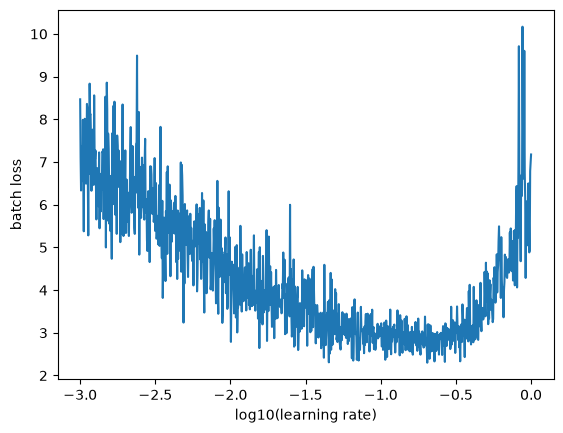

In [8]:
plt.plot(lre, lossi)
plt.xlabel("log10(learning rate)")
plt.ylabel("batch loss")
plt.show()